# Week 15 — Larger networks, better two-step flow predictions?

This lightweight companion analyses **retained, previously verified seed-17 summaries**. It does not train, download weights, or replay missing checkpoints. Read the [lesson and six exercises](../../weeks/week15/larger_networks.md) and [artifact inventory](../../results/week15_capacity_study/README.md).

The six-model suite and original Transolver use different training protocols. Keep their tables separate. Only DeepONet, Geom-DeepONet and SMART have completed matched small/large controls in the six-model suite.

Run with Python 3.11+ in a repository checkout; the data analysis uses only the standard library. Jupyter/IPython supplies the notebook display. No CFD evidence archive, ML framework, GPU or internet connection is needed for these analysis cells.


In [1]:
from pathlib import Path
import csv, json, math, hashlib, runpy
root = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p/'results/week15_capacity_study/native_capacity_results.csv').is_file()), None)
if root is None:
    raise RuntimeError('Open this notebook within a FlowMLLab repository checkout.')
folder = root/'results/week15_capacity_study'
print('Analysis scope: recorded summaries, one training seed per configuration.')
print('Weights replayed by this notebook: no')


Analysis scope: recorded summaries, one training seed per configuration.
Weights replayed by this notebook: no


## 1. Load the two experiments separately

An empty CSV field means **unavailable**, not zero. Each aggregate score is the arithmetic mean of 19 case-level errors across eight geometries, not a pooled field norm, geometry mean, or seed mean. Geometry-aware DeepONet in this study receives the full SDF in its branch; it is not the historical Reynolds-only baseline.


In [2]:
def read_csv(name):
    with (folder/name).open(newline='') as f:
        return list(csv.DictReader(f))
native = read_csv('native_capacity_results.csv')
original = read_csv('original_transolver_results.csv')
assert len(native) == 9 and len(original) == 3
assert all(r['seed']=='17' and r['test_cases']=='19' for r in native+original)
for rows, label in ((native,'Six-model suite'), (original,'Original Transolver: separate protocol')):
    print('\n'+label)
    print(f"{'Model / size':43s} {'Velocity %':>12s} {'Reverse IoU':>12s}")
    for r in rows:
        print(f"{r['model']+' / '+r['capacity']:43s} {float(r['velocity_error_pct']):12.4f} {float(r['filtered_reverse_iou']):12.4f}")



Six-model suite
Model / size                                  Velocity %  Reverse IoU
DeepONet / small                                 17.0001       0.3372
DeepONet / large                                 13.8010       0.4381
Geom-DeepONet / small                            12.3153       0.3872
Geom-DeepONet / large                            10.8179       0.3955
SMART / small                                     9.9427       0.4910
SMART / large                                    10.6642       0.4629
DoMINO / large                                   17.5705       0.4602
Geo-FNO / large                                  15.8196       0.3134
GeoTransolver / large                            20.8320       0.3235

Original Transolver: separate protocol
Model / size                                  Velocity %  Reverse IoU
Original Transolver / small                      14.4261       0.4186
Original Transolver scratch / large               5.5128       0.5526
Original Transolver GeoPT transfe

## 2. Calculate the matched capacity effect

Use $100(E_{small}-E_{large})/E_{small}$. A positive value is an error reduction. The case-win counts were retained in prior summaries; missing per-case arrays mean we cannot independently recount them here. They are not 19 independent geometry replications.


In [3]:
pairs = []
for model in ('DeepONet', 'Geom-DeepONet', 'SMART'):
    small = next(r for r in native if r['model']==model and r['capacity']=='small')
    large = next(r for r in native if r['model']==model and r['capacity']=='large')
    es, el = map(float, (small['velocity_error_pct'], large['velocity_error_pct']))
    reduction = 100*(es-el)/es
    iou_change = float(large['filtered_reverse_iou'])-float(small['filtered_reverse_iou'])
    extent_change = float(large['extent_abs_error_H'])-float(small['extent_abs_error_H'])
    pairs.append((model, reduction, iou_change, extent_change))
    print(f'{model:16s} velocity reduction {reduction:+.2f}%; IoU change {iou_change:+.4f}; extent error change {extent_change:+.4f} H')
assert pairs[0][1]>0 and pairs[1][1]>0 and pairs[2][1]<0
assert pairs[0][3]>0  # Lower global velocity error did not improve this extent diagnostic.


DeepONet         velocity reduction +18.82%; IoU change +0.1009; extent error change +0.1211 H
Geom-DeepONet    velocity reduction +12.16%; IoU change +0.0083; extent error change -0.0675 H
SMART            velocity reduction -7.26%; IoU change -0.0281; extent error change +0.0465 H


## 3. Validate the published arithmetic

This checks table integrity and CSV/JSON consistency. It is not a numerical inference replay and cannot validate missing weights, metric source, or CFD accuracy.


In [4]:
analysis = runpy.run_path(str(folder/'analyze_results.py'))
result = analysis['main']()
recorded = json.loads((folder/'paired_comparisons.json').read_text())
assert result == recorded
print('PASS: retained comparisons agree with the executable summary analysis.')


{
  "meaning": "Positive velocity reduction means lower error for the larger model; negative means deterioration. Changes describe this one seed only.",
  "paired_native_capacity": [
    {
      "model": "DeepONet",
      "velocity_error_reduction_pct": 18.817716130331718,
      "filtered_iou_change": 0.10090461298476938,
      "extent_error_change_H": 0.1210526315789473,
      "cases_with_lower_velocity_error": 16,
      "case_win_count_provenance": "Retained run summary; per-case arrays unavailable for re-counting",
      "case_count": 19,
      "seed_count": 1
    },
    {
      "model": "Geom-DeepONet",
      "velocity_error_reduction_pct": 12.15879989568758,
      "filtered_iou_change": 0.008334922603267847,
      "extent_error_change_H": -0.06754385964912274,
      "cases_with_lower_velocity_error": 14,
      "case_win_count_provenance": "Retained run summary; per-case arrays unavailable for re-counting",
      "case_count": 19,
      "seed_count": 1
    },
    {
      "model": "

## 4. Inspect CFD and enlarged-network contours

These retained g049 figures use each field's own streamlines and a shared banded speed scale. Labels describe the displayed case. Original Transolver is a visual reference from a separate training protocol. Inspect streamline direction to identify reverse flow; speed magnitude alone does not reveal the sign of $u$.


DoubleStep_All_Large_Models_Re100.png
DoubleStep_All_Large_Models_Re25.png
CFD_vs_Large_Networks_Re100.png


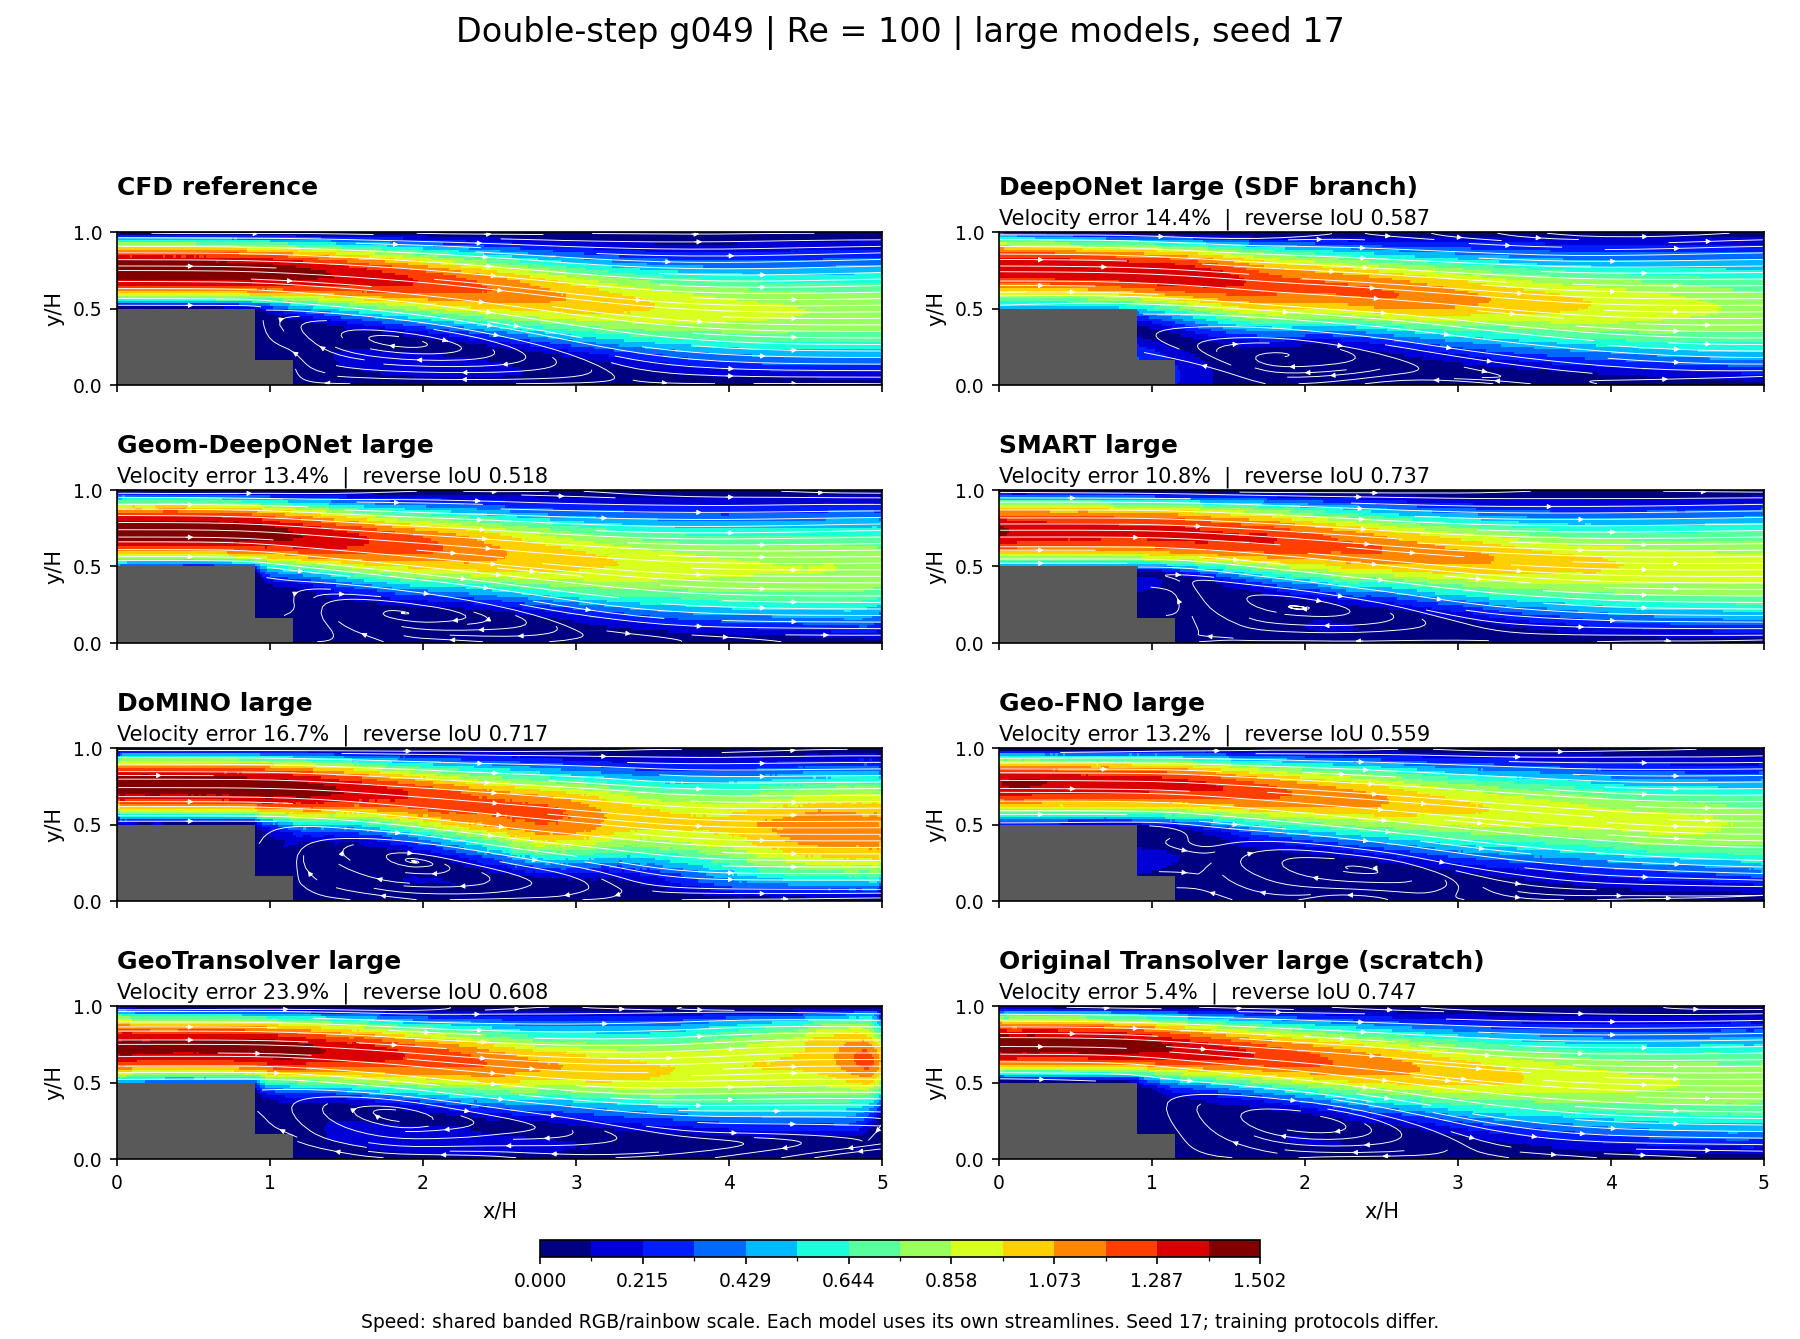

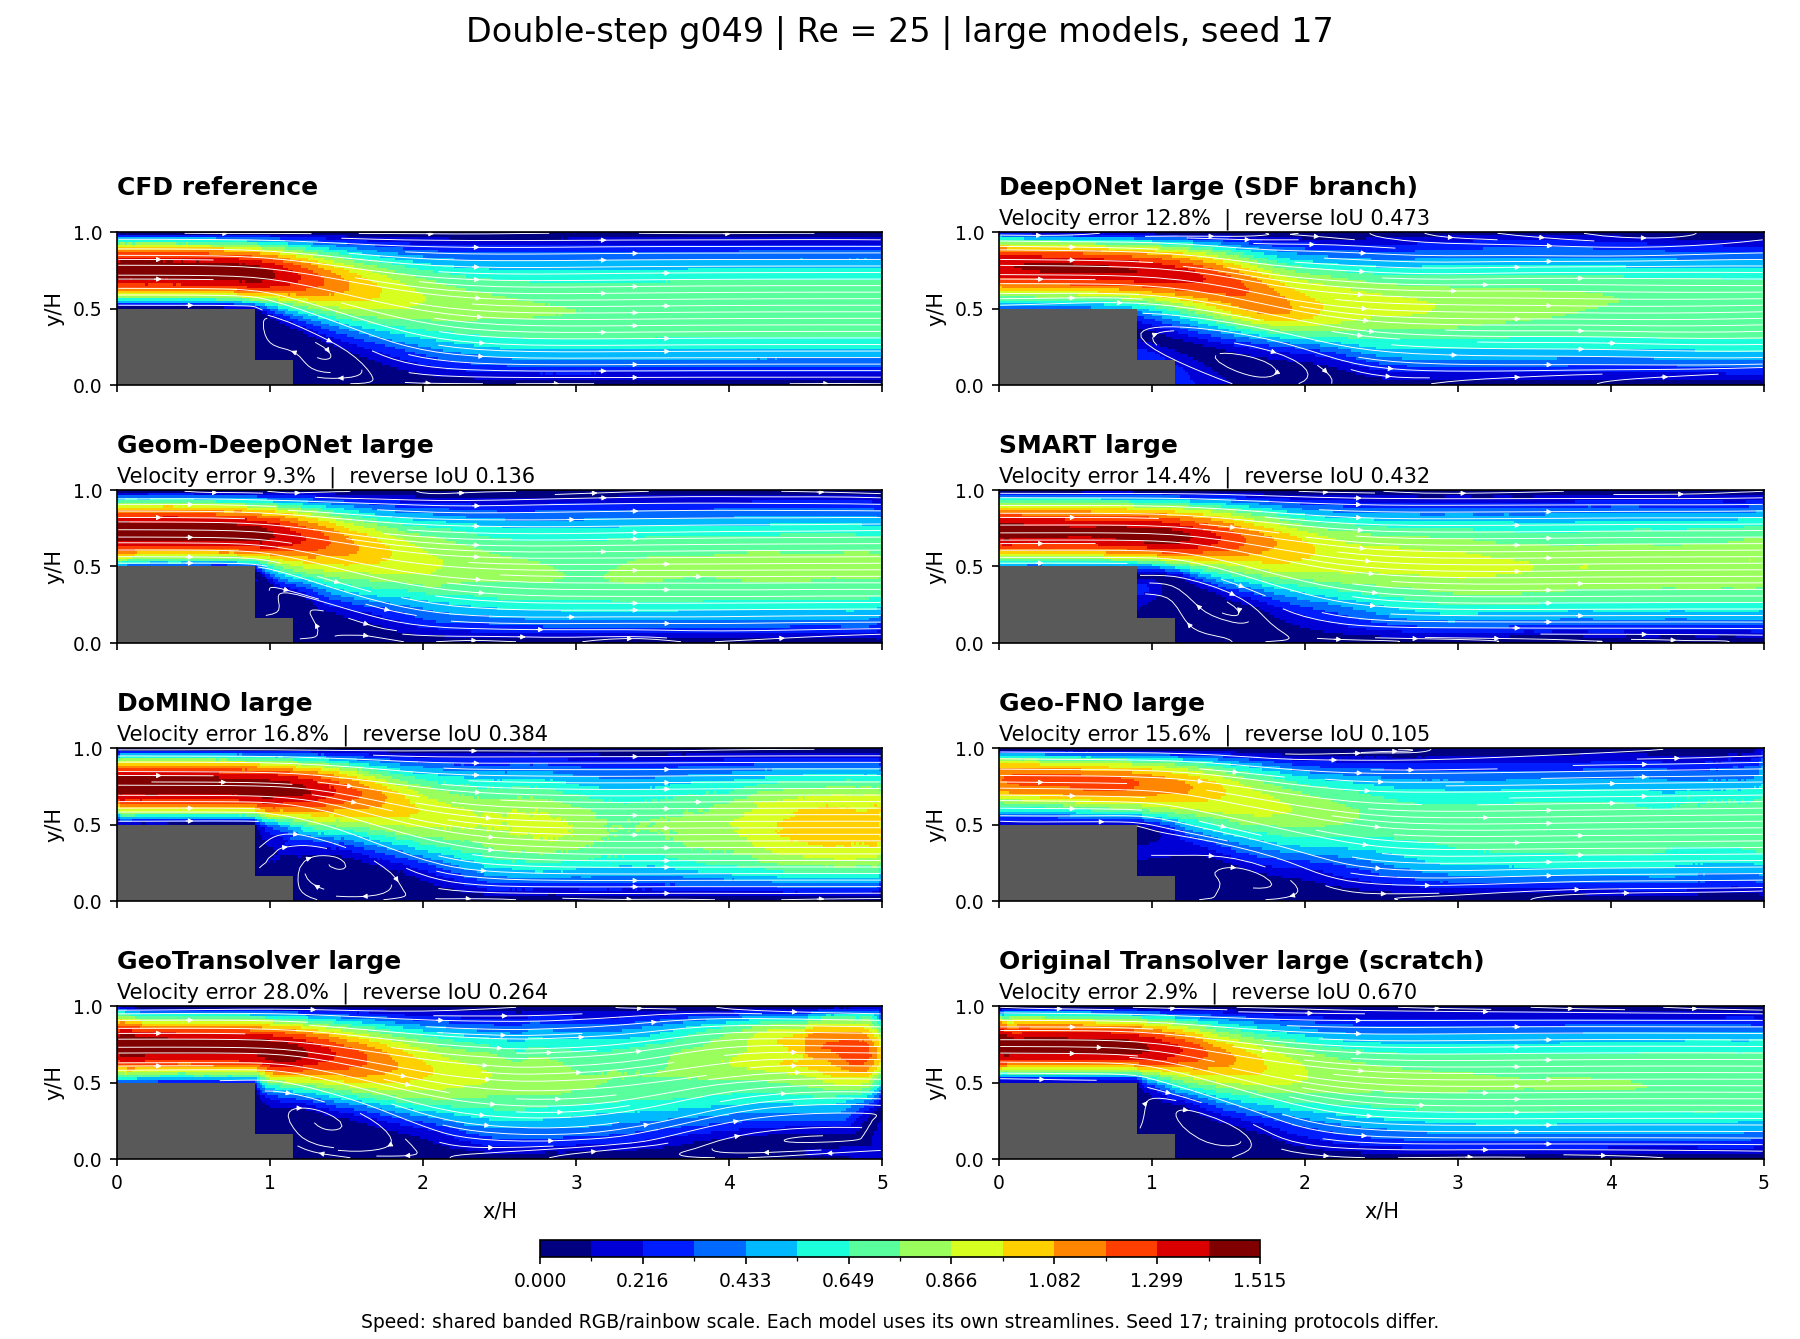

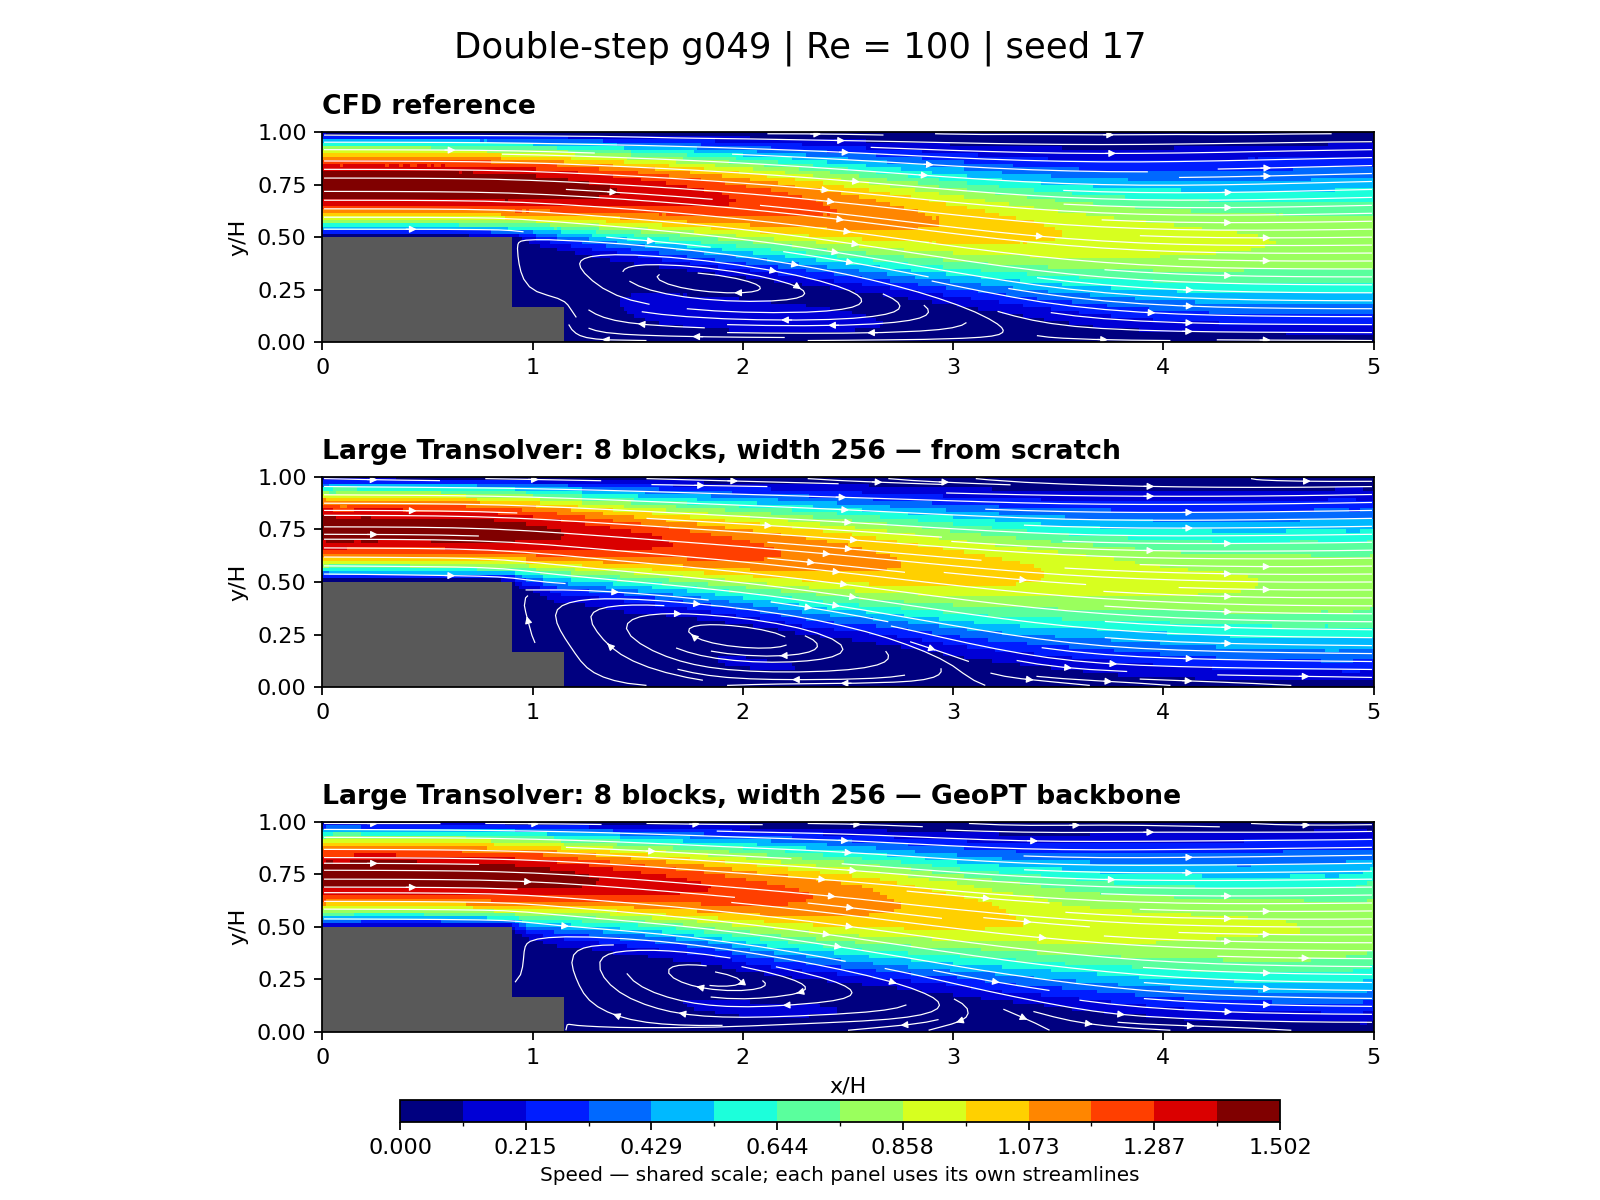

In [5]:
from IPython.display import display, Image
for name in ('DoubleStep_All_Large_Models_Re100.png', 'DoubleStep_All_Large_Models_Re25.png', 'CFD_vs_Large_Networks_Re100.png'):
    print(name)
    display(Image(filename=str(folder/'figures'/name), width=1000))


## 5. GeoPT: an attractive case versus the test mean

Compare the Re=100 example with the 19-case means. GeoPT transfers a compatible original-Transolver backbone. It does not initialize the other six architectures or reproduce the original 3D prompt setup.


In [6]:
cases = read_csv('g049_Re100_results.csv')
scratch = next(r for r in original if r['model']=='Original Transolver scratch')
transfer = next(r for r in original if r['model']=='Original Transolver GeoPT transfer')
for key in ('velocity_error_pct', 'pressure_error_pct', 'filtered_reverse_iou'):
    print(f"Mean {key}: scratch={float(scratch[key]):.4f}; GeoPT={float(transfer[key]):.4f}")
for r in cases:
    if r['model'].startswith('Original Transolver'):
        print(f"g049/Re100 {r['model']}: velocity={float(r['velocity_error_pct']):.4f}%; IoU={float(r['filtered_reverse_iou']):.4f}")
assert float(transfer['velocity_error_pct']) > float(scratch['velocity_error_pct'])


Mean velocity_error_pct: scratch=5.5128; GeoPT=6.1150
Mean pressure_error_pct: scratch=59.3233; GeoPT=57.2614
Mean filtered_reverse_iou: scratch=0.5526; GeoPT=0.4911
g049/Re100 Original Transolver: velocity=21.5030%; IoU=0.6501
g049/Re100 Original Transolver scratch: velocity=5.3602%; IoU=0.7465
g049/Re100 Original Transolver GeoPT transfer: velocity=4.5733%; IoU=0.8008


## 6. Equal updates do not isolate architecture

The native suite uses derivative stencils, a reverse-zone/vorticity loss and a physical validation score. Original Transolver uses uniform points, mean/std scaling and normalized field MSE. Nominal query rows are not unique samples or FLOPs.


In [7]:
protocols = json.loads((folder/'protocols.json').read_text())
for name in ('native_capacity', 'original_transolver'):
    p = protocols[name]
    print(name, 'updates =', p['optimizer_updates'], '; nominal sampled rows =', p['optimizer_updates']*p['training_rows_per_update'])
    print('  Loss:', p['loss'])
    print('  Selection:', p['checkpoint_selection'])
assert 19200*512 == 9830400 and 19200*1024 == 19660800


native_capacity updates = 19200 ; nominal sampled rows = 9830400
  Loss: RMS-scaled field MSE + 0.25 training reverse-zone velocity MSE + 0.1 five-point-stencil vorticity MSE
  Selection: Best validation score, not test score
original_transolver updates = 19200 ; nominal sampled rows = 19660800
  Loss: Unweighted normalized u/v/pressure MSE
  Selection: Best validation MSE


## 7. Audit evidence and weight availability

A new process reloaded the selected checkpoints before the environment reset. That checks inference reconstruction, not training variability. The new trained weights, arrays and original replay reports are currently unavailable. The old compact original-Transolver checkpoint survives in the existing repository. Recorded hashes of missing files are identifiers, not downloads.


In [8]:
ledger = json.loads((folder/'artifact_availability.json').read_text())
for item in ledger['artifacts']:
    print(item['kind'] + ': ' + item['status'])
for p in sorted((folder/'figures').glob('*.png')):
    print('Figure SHA256:', p.name, hashlib.sha256(p.read_bytes()).hexdigest())
assert sum(r['checkpoint_available']=='True' for r in original)==1
assert all(r['checkpoint_available']=='False' for r in native)


summary metrics: retained and published
summary analysis: published and rerunnable
architecture and protocol descriptions: retained and published
large-model figures: retained raster figures
new native-suite trained weights: unavailable after environment reset
compact original Transolver trained weights: available in existing main repository
new original-Transolver trained weights: unavailable after environment reset
new per-case predictions, full metric ledgers and training histories: unavailable after environment reset
six-model training adapters: unavailable after environment reset
original Transolver experiment source: recovered source published in this release
official GeoPT pretrained source: upstream reference
DoMINO, Geo-FNO and GeoTransolver small controls: cancelled by user
Figure SHA256: CFD_vs_Large_Networks_Re100.png fa222829fb47d11250abecf6aa95ee5f677048b3bcd537094e9099cf63954428
Figure SHA256: DoubleStep_All_Large_Models_Re100.png 98e07850cdb0cb736cd4c0bd7a5aea42aacb49a1

## 8. Your decision memo

Use the six exercises and instructor notes in the [lesson](../../weeks/week15/larger_networks.md#11-student-exercises). Before running anything further, answer:

1. Which engineering objective and primary metric will determine your decision?
2. Which result is a matched capacity comparison, and which is merely a large-model observation?
3. Which small/large pair merits three common training seeds first?
4. How will you preserve source, scaling, best/resumable weights, all per-case fields and replay evidence outside a transient session?
5. Since this test has been inspected, what untouched holdout would support a stronger generalization claim?

**Expected conclusion:** capacity helped two completed native pairs and hurt one under this protocol and seed. Velocity, overlap and footprint extent can disagree. Select a finite next experiment from the physical objective and evidence gaps, not from one attractive contour.
